# Part 3 — Final Results & Charts (no re-benchmark)

This notebook **reads the existing Stage 2 FULL report ZIP** and regenerates three figures, benchmark summary, and validation checks. It does **not** read 43 years of Financials or rerun Polars/Spark benchmarks.

**Prerequisites:** run the Stage 1 correctness pilot and the Stage 2 FULL benchmark separately. Provide the ZIP `FDIC_Part3_Stage2_Benchmark_Reports.zip` generated by Stage 2 FULL.

**Deliverables:** 3 high-resolution PNG figures + `Part3_final_metrics.csv` + `Part3_Final_Charts.zip`.

In [ ]:
# Setup: can run in Google Colab or local Jupyter
import io, json, zipfile, pathlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPORT_ZIP = pathlib.Path('/content/FDIC_Part3_Stage2_Benchmark_Reports.zip')  # change if stored elsewhere
OUT = pathlib.Path('/content/FDIC_Part3_Final_Charts')
OUT.mkdir(parents=True, exist_ok=True)

if not REPORT_ZIP.exists():
    try:
        from google.colab import files
        print('Upload your Stage 2 FULL ZIP from Google Drive or your computer:')
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith('.zip')]
        if len(candidates) != 1:
            raise ValueError('Upload exactly one ZIP or set REPORT_ZIP manually.')
        REPORT_ZIP = pathlib.Path('/content') / candidates[0]
    except ImportError:
        raise FileNotFoundError(f'ZIP not found: {REPORT_ZIP}; set REPORT_ZIP to your local path.')
assert REPORT_ZIP.exists(), REPORT_ZIP
print('Input ZIP:', REPORT_ZIP)

Upload your Stage 2 FULL ZIP from Google Drive or your computer:


Saving FDIC_Part3_Stage2_Benchmark_Reports (2).zip to FDIC_Part3_Stage2_Benchmark_Reports (2).zip
Input ZIP: /content/FDIC_Part3_Stage2_Benchmark_Reports (2).zip


In [ ]:
# Load original Stage 2 reports directly from ZIP (no extraction required)
with zipfile.ZipFile(REPORT_ZIP) as z:
    def readcsv(name):
        return pd.read_csv(io.BytesIO(z.read(name)))
    summary = json.loads(z.read('stage2_summary.json'))
    bench = readcsv('stage2_benchmark_summary.csv')
    raw_timings = readcsv('stage2_raw_timings.csv')
    parity = readcsv('stage2_parity_results.csv')
    edge = readcsv('stage2_edge_case_checks.csv')
    gates = readcsv('stage2_acceptance_gates.csv')

assert summary['run_mode'] == 'FULL', 'This is not a FULL benchmark report.'
assert len(gates) == 8 and (gates.status == 'PASS').all()
assert len(edge) == 53 and (edge.status == 'PASS').all()
assert len(parity) == 240 and (parity.status == 'PASS').all()
assert summary['scales']['S100']['rows'] == 1682616
print('FULL report verified: 8/8 acceptance gates, 53/53 edge cases, 240/240 parity comparisons.')
print('Spark skipped scales:', summary['spark_skipped_scales'])

FULL report verified: 8/8 acceptance gates, 53/53 edge cases, 240/240 parity comparisons.
Spark skipped scales: ['S50', 'S75']


In [ ]:
# Transparent summary tables
def metric(scale, engine, workload, key='median_elapsed_ms'):
    v = bench.loc[(bench.scale == scale) & (bench.engine == engine) &
                  (bench.workload == workload), key]
    if len(v) != 1:
        raise ValueError(f'Expected one row: {scale}, {engine}, {workload}; got {len(v)}')
    return float(v.iloc[0])

full = bench.loc[bench.scale == 'S100'].copy()
full['median_seconds'] = full['median_elapsed_ms'] / 1000
cols = ['engine', 'workload', 'median_seconds', 'median_peak_rss_mib', 'repeats']
display(full[cols].sort_values(['workload','engine']))

stat = []
for w in ['W1_FILTER', 'W2_CLEAN_QA', 'W3_END_TO_END']:
    pol = metric('S100', 'polars', w)
    pd_ms = metric('S100', 'pandas', w)
    spark = metric('S100', 'spark', w)
    stat.append({'workload':w, 'pandas_s':pd_ms/1000,'polars_s':pol/1000,
                 'spark_local_s':spark/1000,'pandas_over_polars_speedup':pd_ms/pol})
metrics = pd.DataFrame(stat)
metrics.to_csv(OUT/'Part3_final_metrics.csv',index=False)
display(metrics)

,engine,workload,median_seconds,median_peak_rss_mib,repeats
0,pandas,W1_FILTER,0.613843,249.414,5
3,polars,W1_FILTER,0.012834,147.871,5
6,spark,W1_FILTER,2.391476,758.676,3
1,pandas,W2_CLEAN_QA,1.897966,1242.652,5
4,polars,W2_CLEAN_QA,0.368308,458.211,5
7,spark,W2_CLEAN_QA,6.023092,829.477,3
2,pandas,W3_END_TO_END,4.651299,3112.887,5
5,polars,W3_END_TO_END,1.459988,725.367,5
8,spark,W3_END_TO_END,9.495758,1168.871,3


,workload,pandas_s,polars_s,spark_local_s,pandas_over_polars_speedup
0,W1_FILTER,0.613843,0.012834,2.391476,47.829437
1,W2_CLEAN_QA,1.897966,0.368308,6.023092,5.153203
2,W3_END_TO_END,4.651299,1.459988,9.495758,3.185847


## Figure 1 — End-to-end scalability (primary figure)
Use the **actual row counts**, not nominal 25/50/75/100%, because the cumulative year samples differ in size. Spark has only two measured points and is **not joined by a line**.

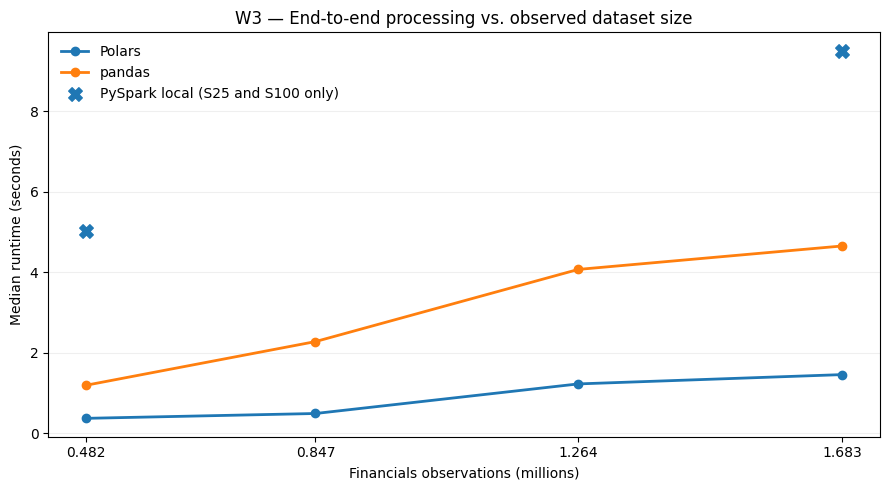

In [ ]:
scales=['S25','S50','S75','S100']
rows = [summary['scales'][s]['rows'] / 1e6 for s in scales]
fig,ax=plt.subplots(figsize=(9,5))
for engine,label in [('polars','Polars'),('pandas','pandas')]:
    times=[metric(s,engine,'W3_END_TO_END')/1000 for s in scales]
    ax.plot(rows,times,marker='o',linewidth=2,label=label)
spark_rows=[rows[0],rows[-1]]
spark_times=[metric(s,'spark','W3_END_TO_END')/1000 for s in ('S25','S100')]
ax.scatter(spark_rows,spark_times,marker='X',s=95,label='PySpark local (S25 and S100 only)')
ax.set_xticks(rows,[f'{x:.3f}' for x in rows])
ax.set(xlabel='Financials observations (millions)',ylabel='Median runtime (seconds)',
       title='W3 — End-to-end processing vs. observed dataset size')
ax.grid(axis='y',alpha=.2); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT/'Figure_1_W3_Scalability.png',dpi=180,bbox_inches='tight')
plt.show()

## Figure 2 — Full-sample W3 runtime comparison
Focus the plot on W3, the pipeline closest to Part 2. Report the W1–W3 workload results in a table rather than making three charts with nearly identical messages.

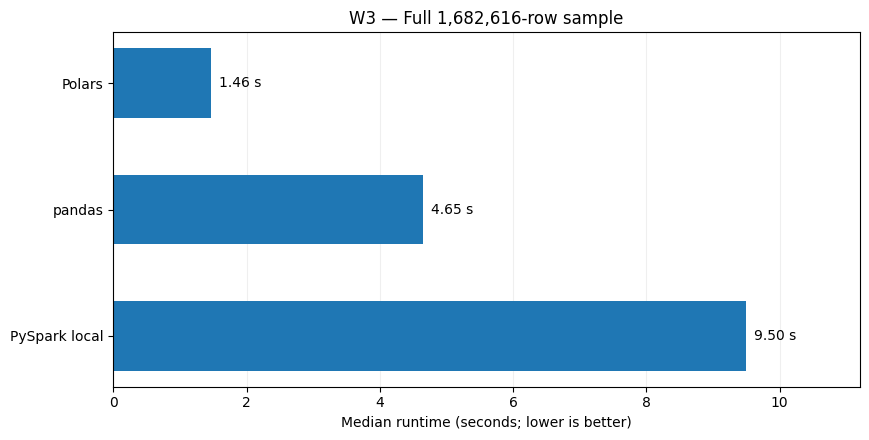

In [ ]:
labels=['Polars','pandas','PySpark local']
engine_keys=['polars','pandas','spark']
runtimes=[metric('S100',e,'W3_END_TO_END')/1000 for e in engine_keys]
fig,ax=plt.subplots(figsize=(8.8,4.5))
bars=ax.barh(labels,runtimes,height=.55); ax.invert_yaxis()
for b,n in zip(bars,runtimes):
    ax.text(n+.12,b.get_y()+b.get_height()/2,f'{n:.2f} s',va='center')
ax.set_xlim(0,max(runtimes)*1.18)
ax.set(xlabel='Median runtime (seconds; lower is better)',title='W3 — Full 1,682,616-row sample')
ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig(OUT/'Figure_2_W3_Full_Runtime.png',dpi=180,bbox_inches='tight')
plt.show()

## Figure 3 — Full-sample sampled peak memory
This is **sampled worker+child-process RSS**, not dataframe-only allocations. Spark includes JVM overhead. Sampling interval: 40 ms.

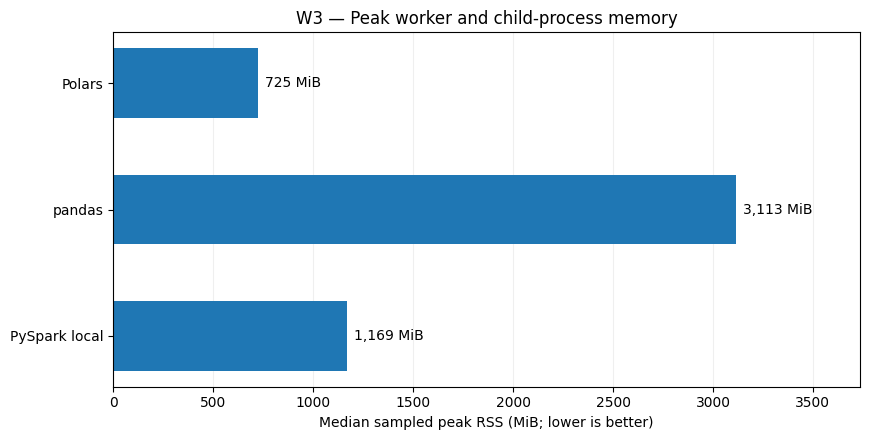

In [ ]:
mem=[metric('S100',e,'W3_END_TO_END','median_peak_rss_mib') for e in engine_keys]
fig,ax=plt.subplots(figsize=(8.8,4.5))
bars=ax.barh(labels,mem,height=.55);ax.invert_yaxis()
for b,n in zip(bars,mem):
    ax.text(n+35,b.get_y()+b.get_height()/2,f'{n:,.0f} MiB',va='center')
ax.set_xlim(0,max(mem)*1.2)
ax.set(xlabel='Median sampled peak RSS (MiB; lower is better)',
       title='W3 — Peak worker and child-process memory')
ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig(OUT/'Figure_3_W3_Full_Peak_RSS.png',dpi=180,bbox_inches='tight')
plt.show()

In [ ]:
# Export outputs. This is a reporting ZIP, not a benchmark rerun.
import zipfile
outzip=OUT.parent/'Part3_Final_Charts.zip'
with zipfile.ZipFile(outzip,'w',zipfile.ZIP_DEFLATED) as zout:
    for f in sorted(OUT.iterdir()):
        if f.is_file(): zout.write(f,f.name)
print('Created:',outzip)
try:
    from google.colab import files
    files.download(str(outzip))
except ImportError:
    pass

Created: /content/Part3_Final_Charts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>